# Mechanical Material Selection for an EV Battery Enclosure using Ashby Screening and TOPSIS

## 1. Problem statement
Choose a sheet-metal alloy for a welded EV battery enclosure that cuts weight without costing too much. We consider temper strength, weld softening, and corrosion as well as density and price.

This analysis uses the supplied dataset in `data.csv`.

## 2. Material behavior in a welded enclosure
- **6061-T6:** small strengthening precipitates help the base metal resist yielding; weld heat changes them.
- **7075-T6:** precipitation hardening gives high base strength, but conventional fusion welding is problematic because of cracking and strength loss.
- **5052-H32:** cold working raises strength; weld heat can remove some of this work hardening.
- **Weld HAZ:** the heat-affected zone is heated without melting, and its changed microstructure can be softer.
- **Steel bolts:** electrical contact with aluminium plus an electrolyte such as salty water can cause galvanic corrosion; isolation and drainage help.
- **Mg AZ31B-H24:** low density is attractive, but corrosion in wet or salty conditions needs attention and protection.

## 3. Import libraries and create the output folder
Pandas handles tables, NumPy handles calculations, and Matplotlib draws charts. The folder keeps our saved results together.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

os.makedirs("outputs", exist_ok=True)
plt.rcParams["figure.dpi"] = 110

## 4. Load and check the data
We load the supplied values. Corrosion grades map to A=9, B=7, C=5, D=3, E=1. The checks report any missing inputs and keep incomplete candidates out of TOPSIS.

In [2]:
data = pd.read_csv("data.csv", na_values=["TODO"])
for row in data.index:
    for column in data.columns:
        if pd.isna(data.loc[row, column]) or str(data.loc[row, column]).strip() == "":
            print(f"Missing input: {data.loc[row, 'material']} - {column} (CSV row {row + 2}).")

corrosion_map = {"A": 9, "B": 7, "C": 5, "D": 3, "E": 1}
data["corrosion_grade"] = data["corrosion_grade"].str.strip().str.upper()
data["corrosion_score"] = data["corrosion_grade"].map(corrosion_map)
if data["corrosion_score"].isna().any():
    raise ValueError("Please use corrosion grades A, B, C, D, or E.")

numeric_columns = ["density_kg_m3", "yield_MPa", "weld_retention", "price_usd_per_kg"]
for column in numeric_columns:
    data[column] = pd.to_numeric(data[column], errors="raise")
    known = data[column].dropna()
    if not np.isfinite(known).all() or (known <= 0).any():
        raise ValueError(f"Known values in '{column}' must be positive and finite.")
if data[["material", "density_kg_m3", "yield_MPa"]].isna().any().any():
    raise ValueError("Material names, density, and base yield are needed for the charts.")
if (data["weld_retention"] > 1).any():
    raise ValueError("Weld retention must be a fraction above 0 and at most 1.")
if data.empty or data["material"].duplicated().any():
    raise ValueError("Please provide materials with unique names.")
data

,material,density_kg_m3,yield_MPa,weld_retention,corrosion_grade,price_usd_per_kg,corrosion_score
0,Mild steel (baseline),7850,370,1.00,D,0.55,3
1,Al 6061-T6,2700,276,0.48,B,4.00,7
2,Al 5052-H32,2680,193,0.36,A,3.25,9
3,Al 7075-T6,2810,503,0.57,D,5.75,3
4,Mg AZ31B-H24,1770,214,0.85,E,2.30,1


## 5. Ashby step 1: calculations
Welded yield = base yield multiplied by weld retention. The strong-panel index is `sqrt(yield) / density`, scaled by 1000 for readability. Higher values indicate better lightweight potential for a strength-limited panel in bending.

The model uses fixed panel plan dimensions and adjustable thickness: bending capacity scales with yield times thickness squared, and mass with density times thickness. Yield is in MPa and density in kg/m^3.

The supplied 7075 and magnesium factors describe ultimate tensile strength (UTS) efficiency. Applying them to yield strength here is a study assumption, not a measured welded-yield value. The factors also correspond to different joining processes (TIG and FSW).

In [3]:
# Multiply by retention to estimate yield after welding.
data["yield_after_weld_MPa"] = data["yield_MPa"] * data["weld_retention"]
data["ashby_base"] = 1000 * np.sqrt(data["yield_MPa"]) / data["density_kg_m3"]
data["ashby_after_weld"] = 1000 * np.sqrt(data["yield_after_weld_MPa"]) / data["density_kg_m3"]
data.to_csv("outputs/ashby_calculations.csv", index=False)
data

,material,density_kg_m3,yield_MPa,weld_retention,corrosion_grade,price_usd_per_kg,corrosion_score,yield_after_weld_MPa,ashby_base,ashby_after_weld
0,Mild steel (baseline),7850,370,1.00,D,0.55,3,370.00,2.450367,2.450367
1,Al 6061-T6,2700,276,0.48,B,4.00,7,132.48,6.153055,4.262961
2,Al 5052-H32,2680,193,0.36,A,3.25,9,69.48,5.183748,3.110249
3,Al 7075-T6,2810,503,0.57,D,5.75,3,286.71,7.981374,6.025805
4,Mg AZ31B-H24,1770,214,0.85,E,2.30,1,181.90,8.264824,7.619791


## 6. Ashby step 2: screening
The study accepts corrosion grade D or better (minimum score 3). A material passes only if it meets the corrosion, price, and after-weld yield limits and has complete inputs. We save every decision and its reason.

In [4]:
minimum_corrosion_score = 3
maximum_price = 5.00
minimum_after_weld_yield = 100

screening_rows = []
for _, material in data.iterrows():
    reasons = []
    if material["corrosion_score"] < minimum_corrosion_score:
        reasons.append("corrosion score below minimum")
    if pd.isna(material["price_usd_per_kg"]):
        reasons.append("price unavailable")
    elif material["price_usd_per_kg"] > maximum_price:
        reasons.append("price above maximum")
    if pd.isna(material["yield_after_weld_MPa"]):
        reasons.append("after-weld yield unavailable (weld retention TODO)")
    elif material["yield_after_weld_MPa"] < minimum_after_weld_yield:
        reasons.append("after-weld yield below minimum")
    status = "PASS"
    reason = "Meets all limits"
    if reasons:
        status = "ELIMINATED"
        reason = "; ".join(reasons)
        print(f"{material['material']}: ELIMINATED - {reason}")
    screening_rows.append([material["material"], status, reason])

screening = pd.DataFrame(screening_rows, columns=["material", "status", "reason"])
passing_names = screening.loc[screening["status"] == "PASS", "material"]
passing = data[data["material"].isin(passing_names)].copy()
screening.to_csv("outputs/screening_result.csv", index=False)
print(f"Materials passing: {len(passing)} of {len(data)}")
screening

Al 5052-H32: ELIMINATED - after-weld yield below minimum
Al 7075-T6: ELIMINATED - price above maximum
Mg AZ31B-H24: ELIMINATED - corrosion score below minimum
Materials passing: 2 of 5


,material,status,reason
0,Mild steel (baseline),PASS,Meets all limits
1,Al 6061-T6,PASS,Meets all limits
2,Al 5052-H32,ELIMINATED,after-weld yield below minimum
3,Al 7075-T6,ELIMINATED,price above maximum
4,Mg AZ31B-H24,ELIMINATED,corrosion score below minimum


## 7. Ashby charts
The log-log chart shows all candidates, including eliminated ones. Circles show base yield, crosses show after-weld yield, and arrows show the change. Density stays the same in this simplified model. Labels identify both points. Only known after-weld values are plotted.

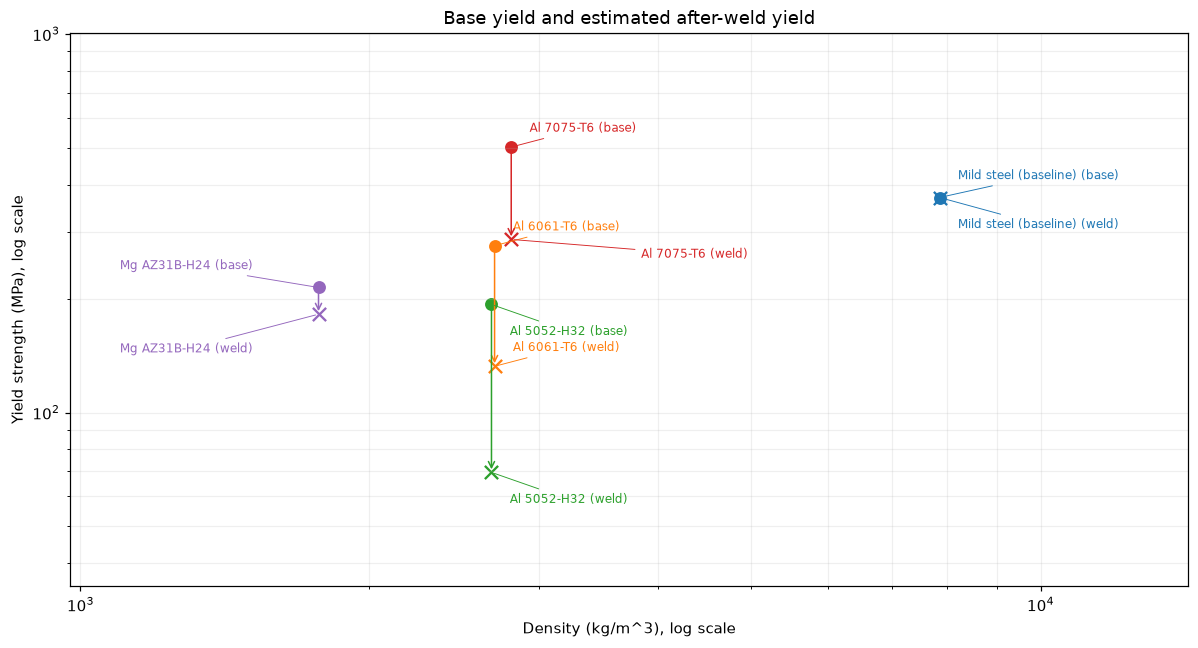

In [5]:
fig, ax = plt.subplots(figsize=(11, 6))
colors = plt.cm.tab10.colors
base_offsets = [(12, 12), (12, 10), (12, -20), (12, 10), (-130, 12)]
weld_offsets = [(12, -20), (12, 10), (12, -20), (85, -12), (-130, -25)]
for i, material in data.iterrows():
    density = material["density_kg_m3"]
    base = material["yield_MPa"]
    welded = material["yield_after_weld_MPa"]
    color = colors[i % len(colors)]
    ax.scatter(density, base, color=color, marker="o", s=55)
    ax.annotate(material["material"] + " (base)", (density, base),
                xytext=base_offsets[i % len(base_offsets)], textcoords="offset points", fontsize=8, color=color,
                arrowprops={"arrowstyle": "-", "color": color, "lw": 0.6})
    if pd.notna(welded):
        ax.scatter(density, welded, color=color, marker="x", s=75)
        if welded < base:
            ax.annotate("", xy=(density, welded), xytext=(density, base),
                        arrowprops={"arrowstyle": "->", "color": color})
        ax.annotate(material["material"] + " (weld)", (density, welded),
                    xytext=weld_offsets[i % len(weld_offsets)], textcoords="offset points", fontsize=8, color=color,
                    arrowprops={"arrowstyle": "-", "color": color, "lw": 0.6})
missing_weld = data.loc[data["yield_after_weld_MPa"].isna(), "material"].tolist()
if missing_weld:
    ax.text(0.02, 0.03, "After-weld values unavailable: " + ", ".join(missing_weld),
            transform=ax.transAxes, fontsize=8)
ax.set_xscale("log")
ax.set_yscale("log")
ax.margins(x=0.40, y=0.35)
ax.set_xlabel("Density (kg/m^3), log scale")
ax.set_ylabel("Yield strength (MPa), log scale")
ax.set_title("Base yield and estimated after-weld yield")
ax.grid(True, which="both", alpha=0.20)
fig.tight_layout()
fig.savefig("outputs/ashby_chart.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

The side-by-side bars compare base yield with the calculated after-weld estimate. Both charts are saved as PNG files.

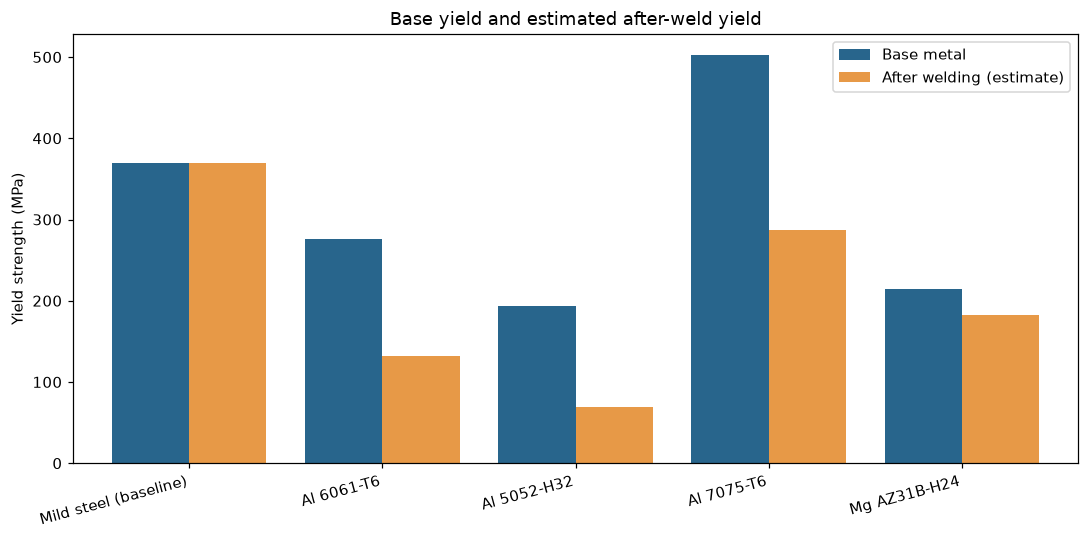

In [6]:
x = np.arange(len(data))
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(x - 0.2, data["yield_MPa"], width=0.4, label="Base metal", color="#28658c")
ax.bar(x + 0.2, data["yield_after_weld_MPa"], width=0.4, label="After welding (estimate)", color="#e79947")
for i, value in enumerate(data["yield_after_weld_MPa"]):
    if pd.isna(value):
        ax.text(i + 0.2, 10, "N/A", ha="center", fontsize=9)
ax.set_xlim(-0.6, len(data) - 0.4)
ax.set_xticks(x)
ax.set_xticklabels(data["material"], rotation=15, ha="right")
ax.set_ylabel("Yield strength (MPa)")
ax.set_title("Base yield and estimated after-weld yield")
ax.legend()
fig.tight_layout()
fig.savefig("outputs/yield_comparison.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

## 8. TOPSIS ranking
The `weights` at the top of this cell follow the order in `columns`: welded yield, weld retention, corrosion, price, and welded Ashby index. The weights represent the balance of priorities used in this analysis. Only price is a cost criterion.

TOPSIS rewards being near the ideal best and far from the ideal worst. It runs only on passing materials. Equal scores share a rank. If all weighted values are identical (including a single candidate), we use neutral closeness 0.5 because the usual formula has a zero denominator. No material is preferred in that case.

In [7]:
weights = [0.25, 0.20, 0.20, 0.15, 0.20]
columns = ["yield_after_weld_MPa", "weld_retention", "corrosion_score",
           "price_usd_per_kg", "ashby_after_weld"]
benefit_flags = [True, True, True, False, True]

def topsis(data, columns, weights, benefit_flags):
    if data.empty:
        raise ValueError("No materials passed. Review the data and screening limits.")
    weights = np.array(weights, dtype=float)
    if len(weights) != len(columns) or len(benefit_flags) != len(columns):
        raise ValueError("Use one weight and one benefit flag per criterion.")
    if not np.isfinite(weights).all() or (weights < 0).any() or not np.isclose(weights.sum(), 1):
        raise ValueError("Weights must be nonnegative, finite, and sum to 1.")
    values = data[columns].to_numpy(dtype=float)

    if not np.isfinite(values).all():
        raise ValueError("TOPSIS needs complete, finite criteria for every passing material.")

    # Step 1: put each column on a comparable scale.
    column_lengths = np.sqrt((values ** 2).sum(axis=0))
    column_lengths[column_lengths == 0] = 1
    normalized = values / column_lengths

    # Step 2: give more influence to criteria with larger weights.
    weighted = normalized * weights

    # Step 3: high is best for benefits, low is best for cost.
    ideal_best = []
    ideal_worst = []
    for j in range(len(columns)):
        if benefit_flags[j]:
            ideal_best.append(weighted[:, j].max())
            ideal_worst.append(weighted[:, j].min())
        else:
            ideal_best.append(weighted[:, j].min())
            ideal_worst.append(weighted[:, j].max())

    # Step 4: measure distance from both ideal combinations.
    distance_best = np.sqrt(((weighted - ideal_best) ** 2).sum(axis=1))
    distance_worst = np.sqrt(((weighted - ideal_worst) ** 2).sum(axis=1))

    # Step 5: larger closeness means a better compromise.
    total_distance = distance_best + distance_worst
    no_difference = total_distance == 0
    total_distance[no_difference] = 1
    closeness = distance_worst / total_distance
    closeness[no_difference] = 0.5
    result = data[["material"] + columns].copy()
    result["closeness"] = closeness.round(12)
    result["rank"] = result["closeness"].rank(ascending=False, method="min").astype(int)
    return result.sort_values("closeness", ascending=False).reset_index(drop=True)

ranking = topsis(passing, columns, weights, benefit_flags)
ranking.to_csv("outputs/topsis_ranking.csv", index=False)
ranking

,material,yield_after_weld_MPa,weld_retention,corrosion_score,price_usd_per_kg,ashby_after_weld,closeness,rank
0,Mild steel (baseline),370.00,1.00,3,0.55,2.450367,0.630722,1
1,Al 6061-T6,132.48,0.48,7,4.00,4.262961,0.369278,2


## 9. Sensitivity analysis
We try four deliberate sets of priorities. Balanced uses the default `weights`. Each list follows the same criterion order and sums to one. We compare each scenario's winner (or tied winners) with Balanced and save a material-by-scenario rank table.

In [8]:
weight_sets = {
    "Balanced": weights,
    "Strength-focused": [0.55, 0.10, 0.10, 0.05, 0.20],
    "Corrosion/welded-focused": [0.10, 0.30, 0.40, 0.05, 0.15],
    "Cost-focused": [0.10, 0.10, 0.10, 0.60, 0.10]
}

rank_table = pd.DataFrame(index=passing["material"])
score_table = pd.DataFrame(index=passing["material"])
winners = {}
changes = []
for scenario, scenario_weights in weight_sets.items():
    result = topsis(passing, columns, scenario_weights, benefit_flags)
    result = result.set_index("material")
    rank_table[scenario] = result["rank"]
    score_table[scenario] = result["closeness"]
    winners[scenario] = sorted(result.index[result["rank"] == 1].tolist())
    print(f"{scenario}: top-ranked = {', '.join(winners[scenario])}")
    if scenario != "Balanced" and winners[scenario] != winners["Balanced"]:
        changes.append(scenario)
        print(f"  Winner changes from Balanced to {', '.join(winners[scenario])}.")
if len(passing) == 1:
    print("Only one material passes: all scenarios assign neutral closeness 0.5; no alternatives are compared.")
elif not changes:
    print("The winner does not change across these weight sets.")
rank_table.to_csv("outputs/sensitivity_ranks.csv", index_label="material")
rank_table

Balanced: top-ranked = Mild steel (baseline)
Strength-focused: top-ranked = Mild steel (baseline)
Corrosion/welded-focused: top-ranked = Al 6061-T6
  Winner changes from Balanced to Al 6061-T6.
Cost-focused: top-ranked = Mild steel (baseline)


,Balanced,Strength-focused,Corrosion/welded-focused,Cost-focused
material,,,,
Mild steel (baseline),1,1,2,1
Al 6061-T6,2,2,1,2


The grouped bars compare closeness within each scenario. Larger scores are preferred, but they are not probabilities and should not be read as absolute performance measures across scenarios.

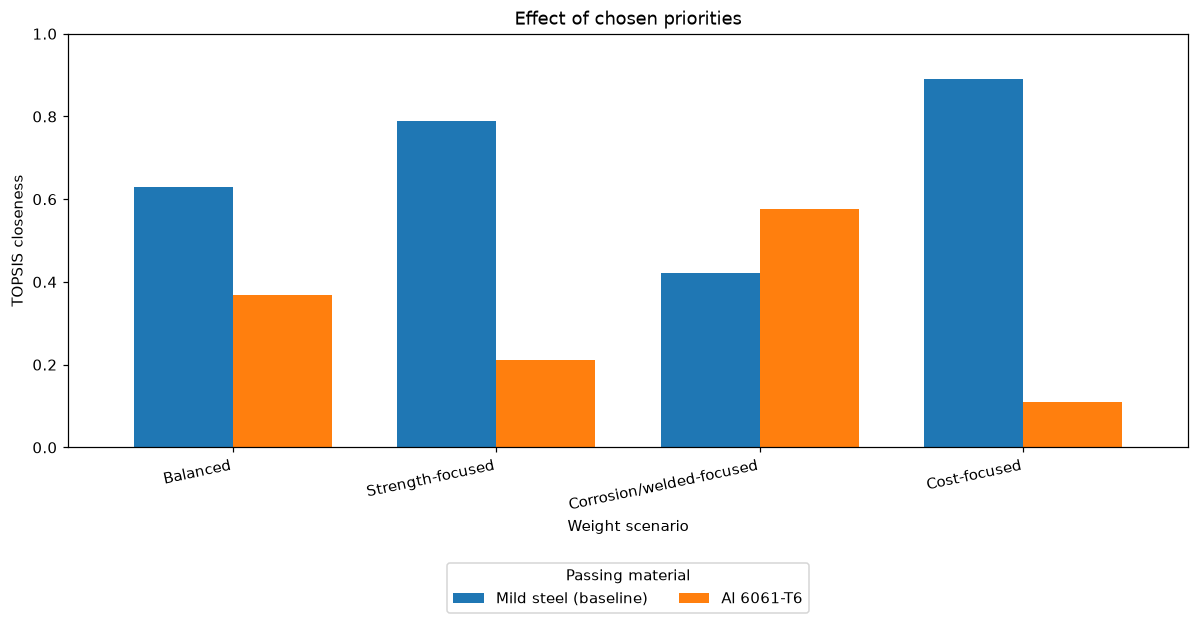

In [9]:
ax = score_table.T.plot(kind="bar", figsize=(11, 6), width=0.75)
ax.set_ylabel("TOPSIS closeness")
ax.set_xlabel("Weight scenario")
ax.set_ylim(0, 1)
ax.set_title("Effect of chosen priorities")
if len(passing) == 1:
    ax.set_title("One passing material: neutral closeness in every scenario")
ax.set_xticklabels(score_table.columns, rotation=12, ha="right")
ax.legend(title="Passing material", loc="upper center", bbox_to_anchor=(0.5, -0.26), ncol=2)
fig = ax.get_figure()
fig.tight_layout()
fig.savefig("outputs/sensitivity_chart.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

## 10. Final summary
The calculated winner and scenario changes are listed below.

In [10]:
best_materials = ranking.loc[ranking["rank"] == 1, "material"].tolist()
if len(passing) == 1:
    print("Only passing material:", ", ".join(best_materials))
    print("TOPSIS closeness is neutral (0.5); there is no competing candidate.")
else:
    print("Best material(s) with default weights:", ", ".join(best_materials))
if changes:
    for scenario in changes:
        print(f"{scenario} changes the winner to {', '.join(winners[scenario])}.")
else:
    print("None of the chosen scenarios changes the winner.")

Best material(s) with default weights: Mild steel (baseline)
Corrosion/welded-focused changes the winner to Al 6061-T6.
